# Cyber Crime Detection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('cyber_train_data.csv')

In [3]:
df.head()

,category,sub_category,crimeaditionalinfo
0,Online and Social Media Related Crime,Cyber Bullying Stalking Sexting,I had continue received random calls and abusi...
1,Online Financial Fraud,Fraud CallVishing,The above fraudster is continuously messaging ...
2,Online Gambling Betting,Online Gambling Betting,He is acting like a police and demanding for m...
3,Online and Social Media Related Crime,Online Job Fraud,In apna Job I have applied for job interview f...
4,Online Financial Fraud,Fraud CallVishing,I received a call from lady stating that she w...


In [4]:
df.shape

(93686, 3)

In [5]:
df.duplicated().sum()

np.int64(7803)

In [6]:
df = df.drop_duplicates()

In [7]:
df.isnull().sum()

category                 0
sub_category          3858
crimeaditionalinfo       7
dtype: int64

In [8]:
df = df.dropna()

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 82018 entries, 0 to 93685
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   category            82018 non-null  str  
 1   sub_category        82018 non-null  str  
 2   crimeaditionalinfo  82018 non-null  str  
dtypes: str(3)
memory usage: 2.5 MB


In [10]:
df.nunique()

category                 11
sub_category             35
crimeaditionalinfo    81189
dtype: int64

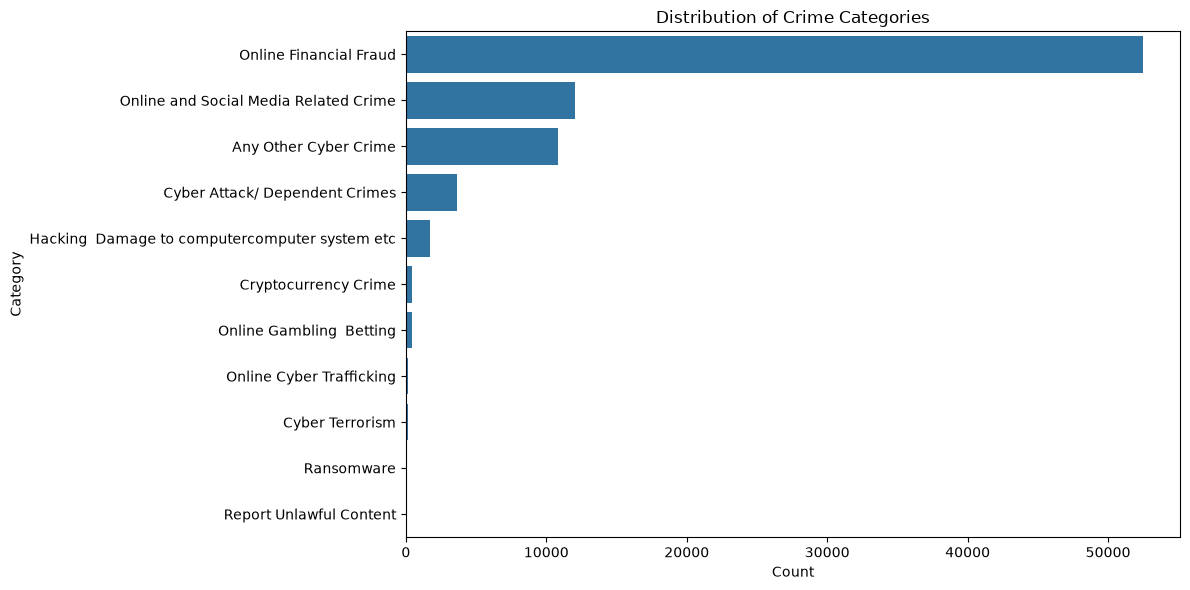

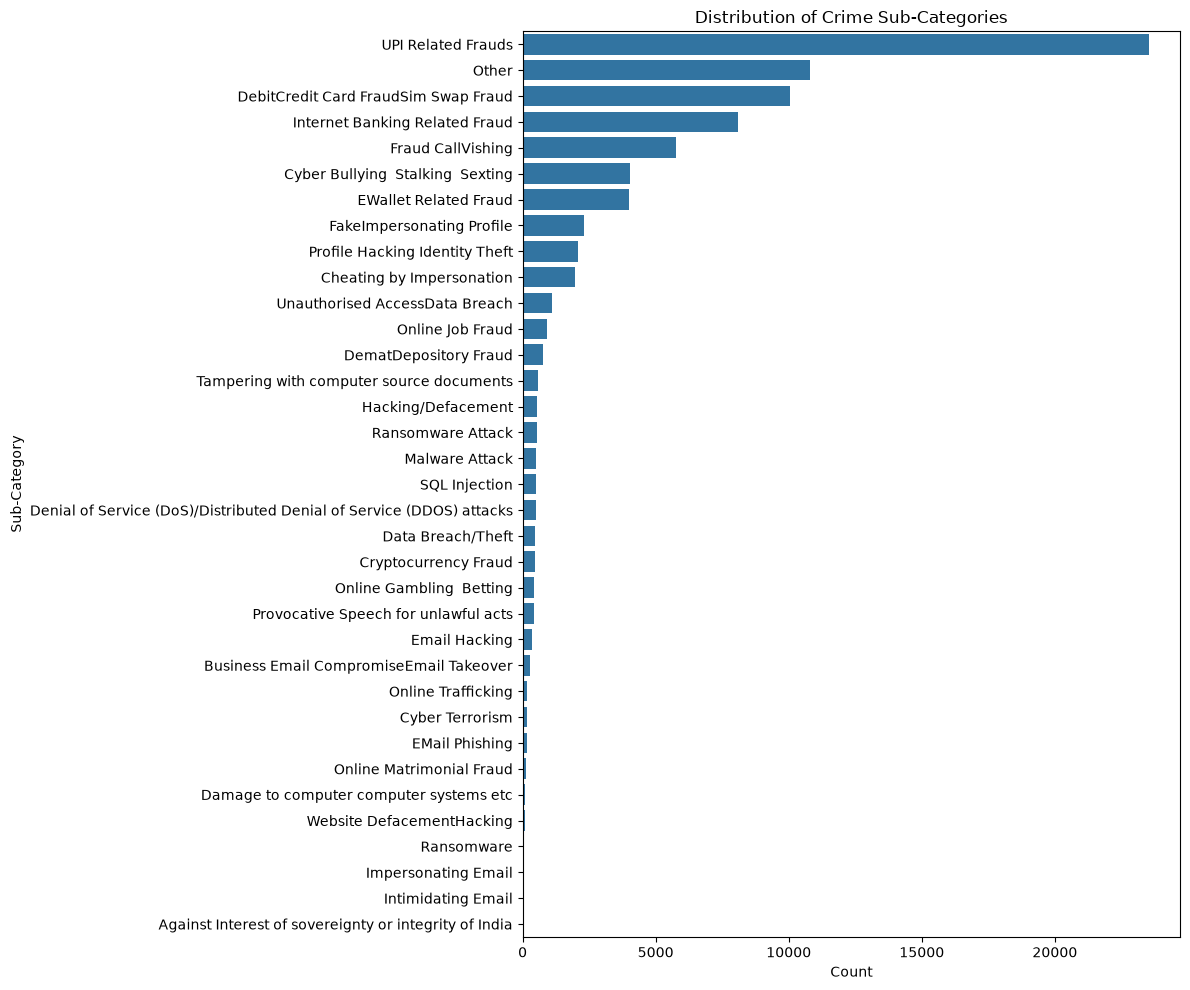

In [11]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    y='category',
    order=df['category'].value_counts().index
)
plt.xlabel('Count')
plt.ylabel('Category')
plt.title('Distribution of Crime Categories')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 10))
sns.countplot(
    data=df,
    y='sub_category',
    order=df['sub_category'].value_counts().index
)
plt.xlabel('Count')
plt.ylabel('Sub-Category')
plt.title('Distribution of Crime Sub-Categories')
plt.tight_layout()
plt.show()

In [12]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('punkt_tab')

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    
    text = text.lower()
  
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    
    text = re.sub(r'[^\x00-\x7F]+', '', text)
    
    text = text.translate(str.maketrans('', '', string.punctuation))
   
    text = re.sub(r'\d+', '', text)
   
    tokens = nltk.word_tokenize(text)
    
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words and word.isalpha()]
    
    clean_text = ' '.join(tokens)
    
    return clean_text

df['crimeaditionalinfo'] = df['crimeaditionalinfo'].apply(preprocess_text)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\saiva\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\saiva\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\saiva\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\saiva\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [14]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
from wordcloud import WordCloud

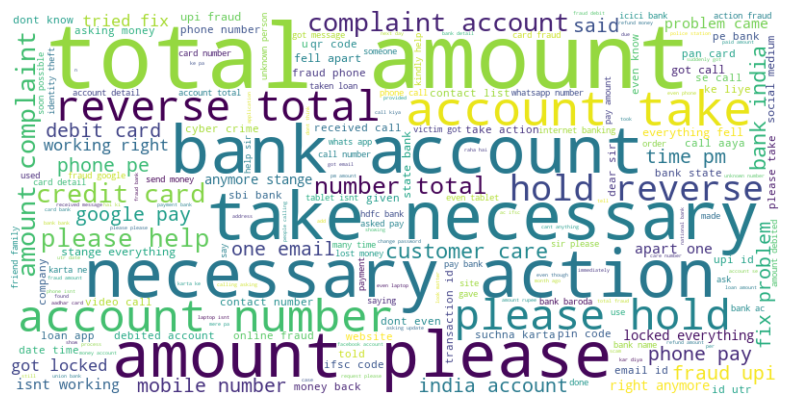

In [16]:
text_for_wordcloud = ' '.join(df['crimeaditionalinfo'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text_for_wordcloud)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off') 
plt.show()

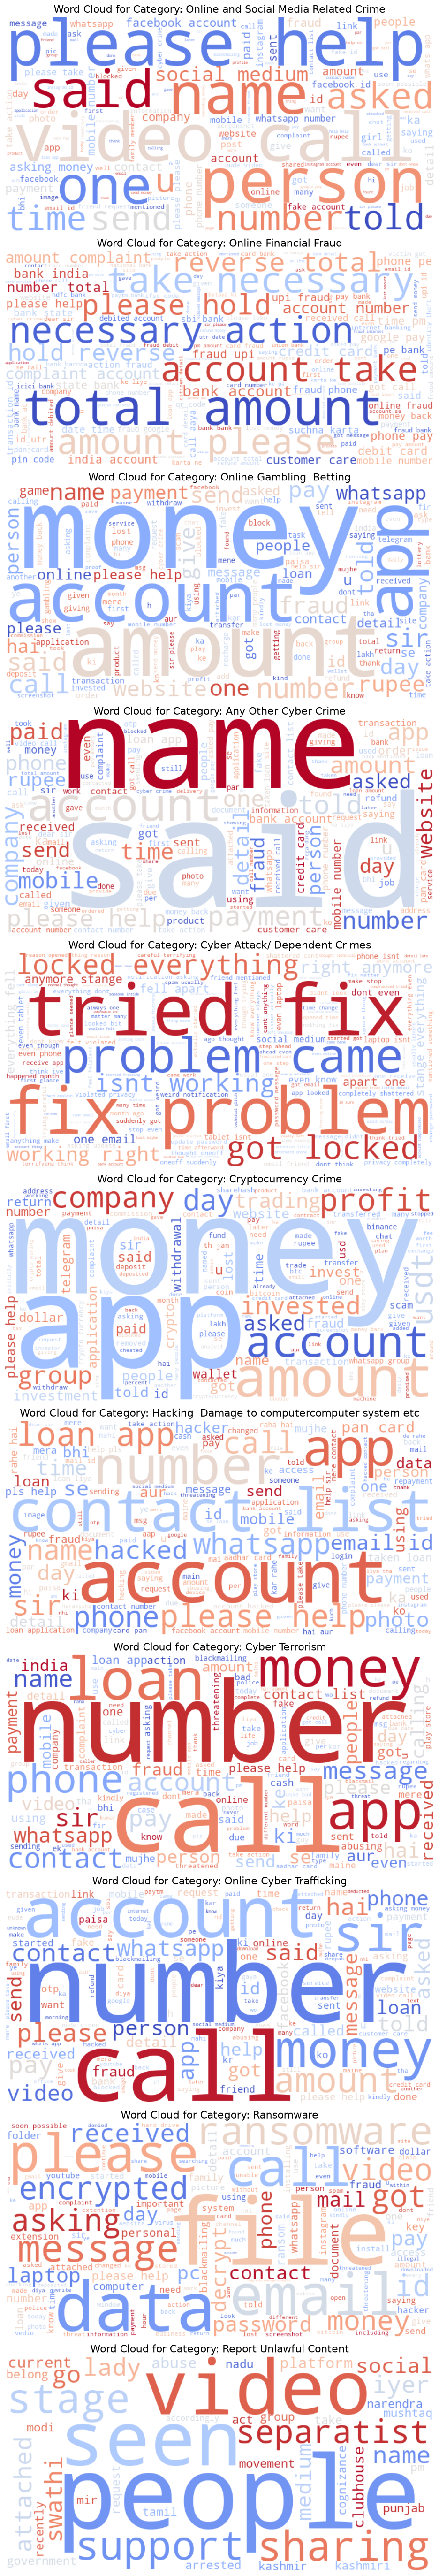

In [17]:
categories = df['category'].unique() 
fig, axes = plt.subplots(len(categories), 1, figsize=(10, 5 * len(categories)))  

for i, category in enumerate(categories):
    text_for_wordcloud = ' '.join(df[df['category'] == category]['crimeaditionalinfo'])
    
    wordcloud = WordCloud(
        width=800, height=400,
        background_color='white',
        colormap='coolwarm',
        max_words=150,
        contour_color='black',
        contour_width=3
    ).generate(text_for_wordcloud)
    
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(f"Word Cloud for Category: {category}", fontsize=16)

plt.tight_layout()
plt.show()

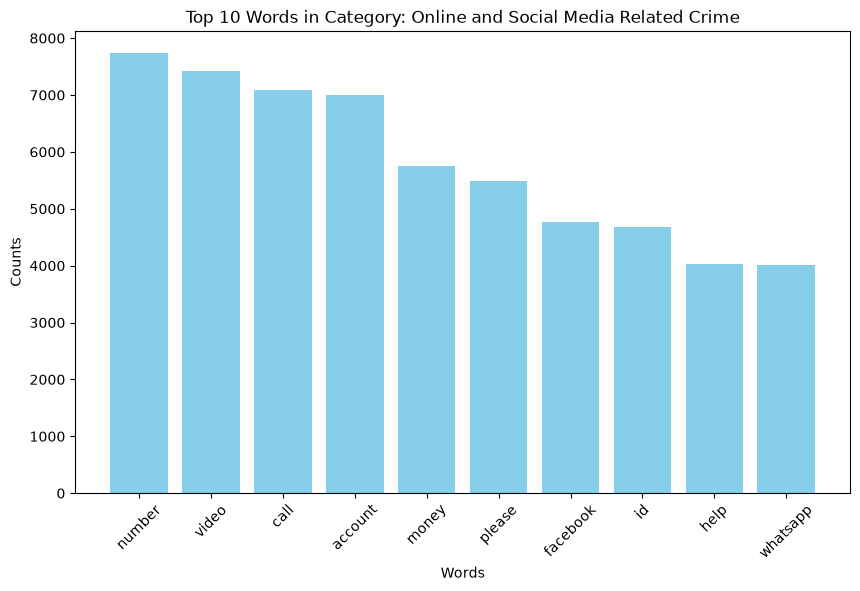

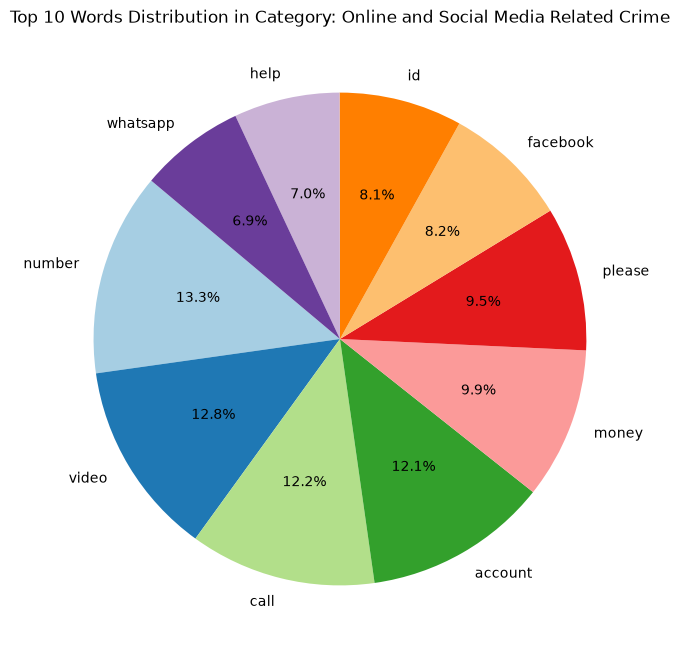

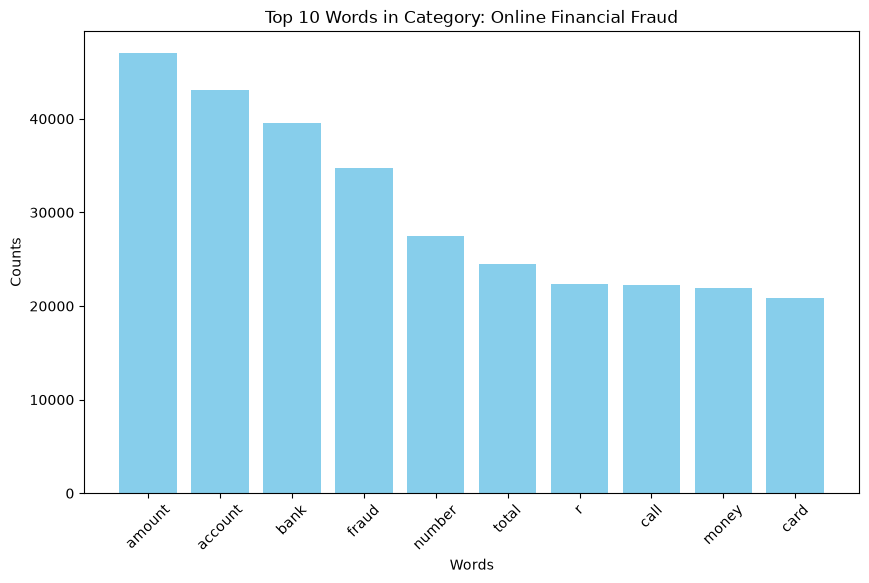

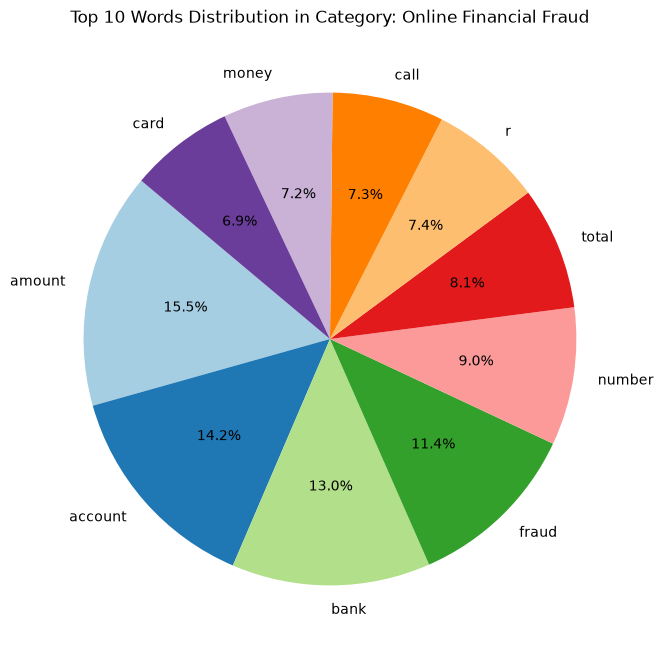

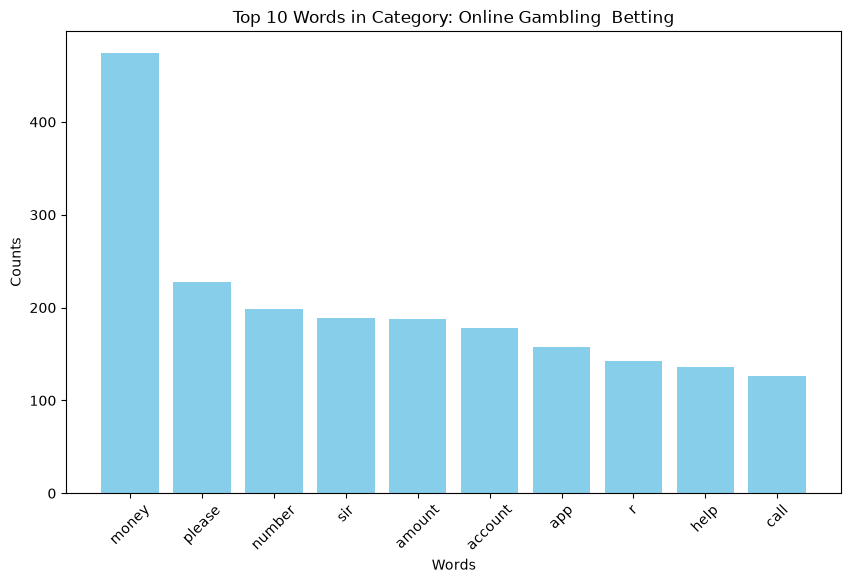

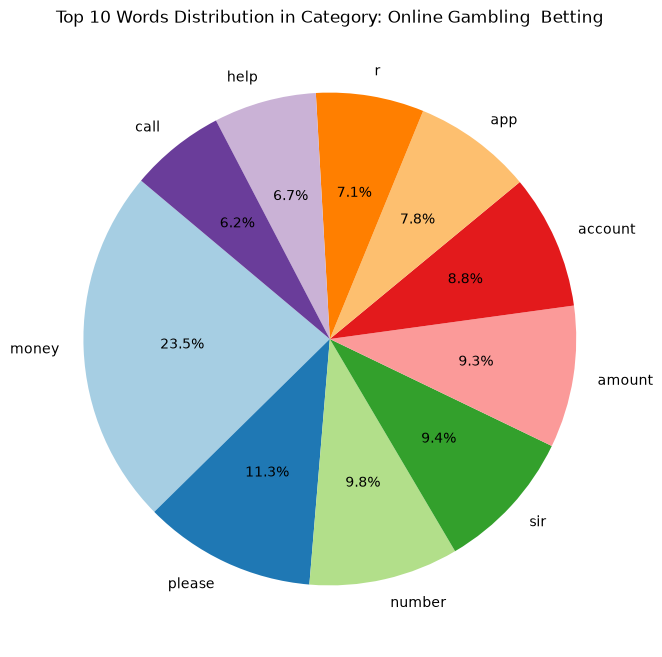

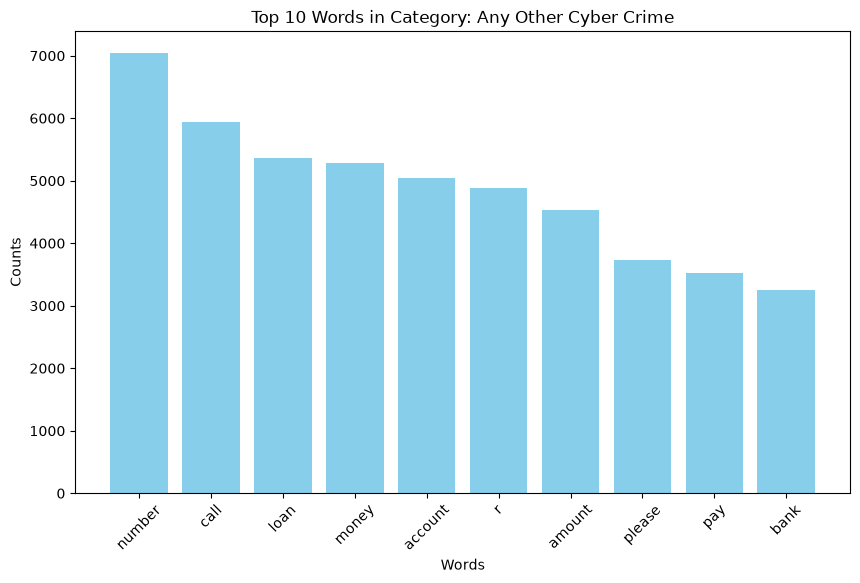

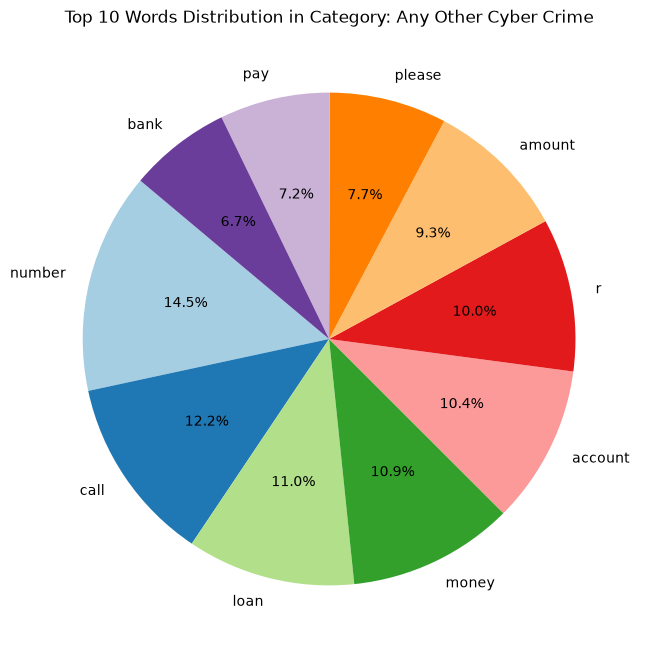

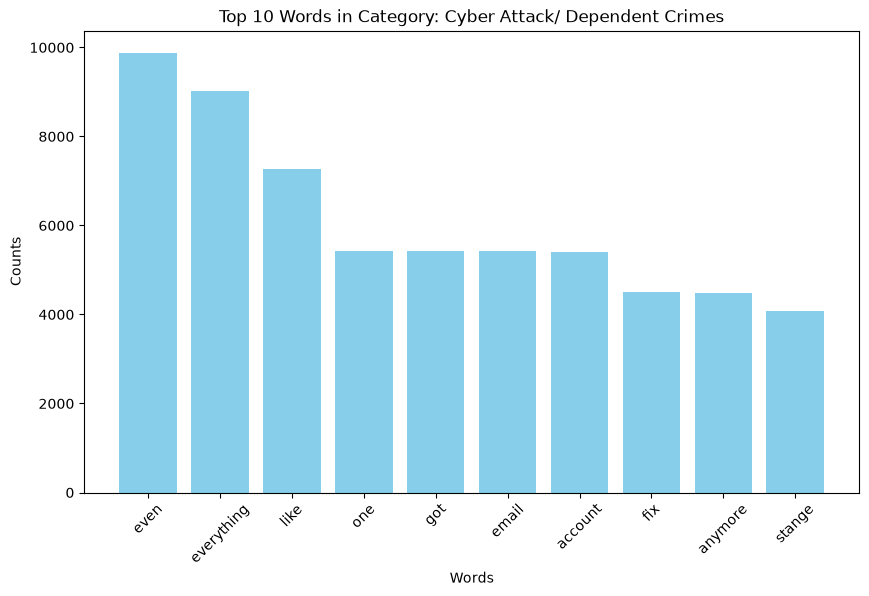

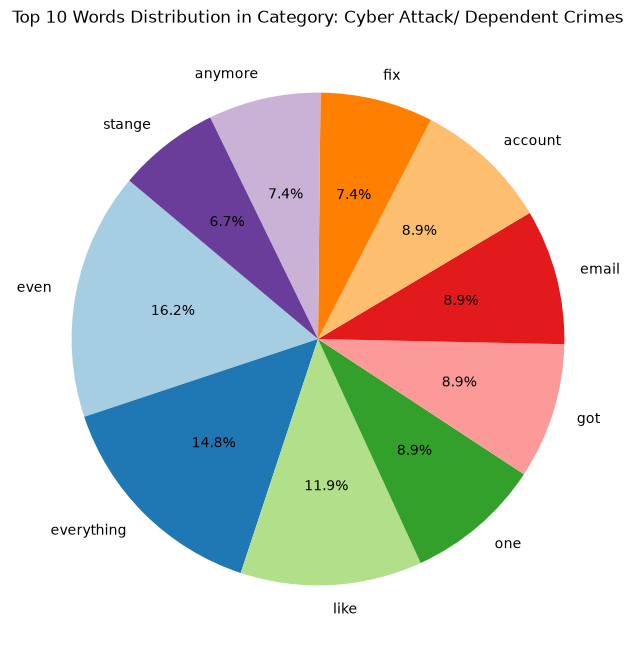

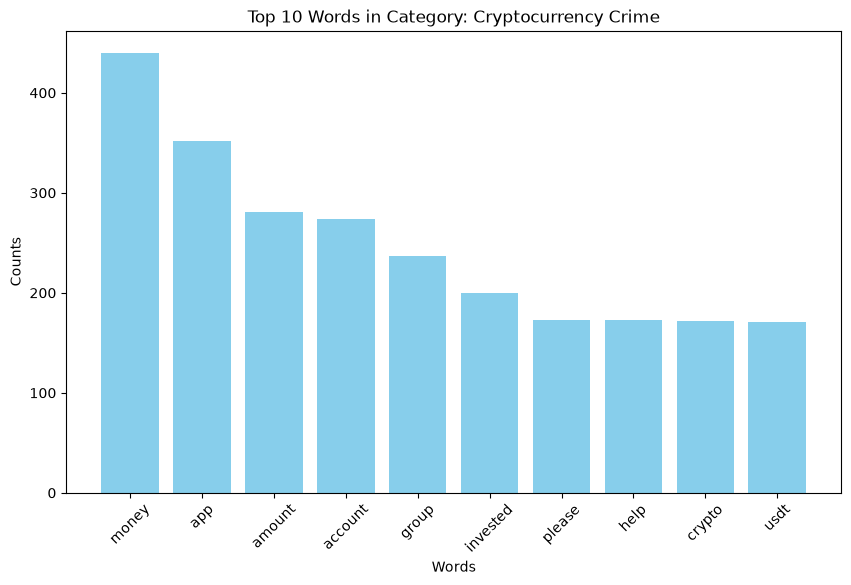

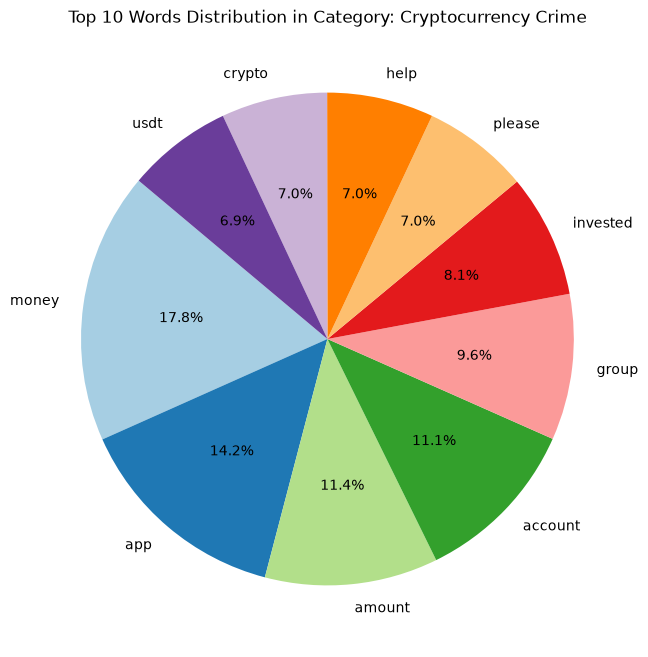

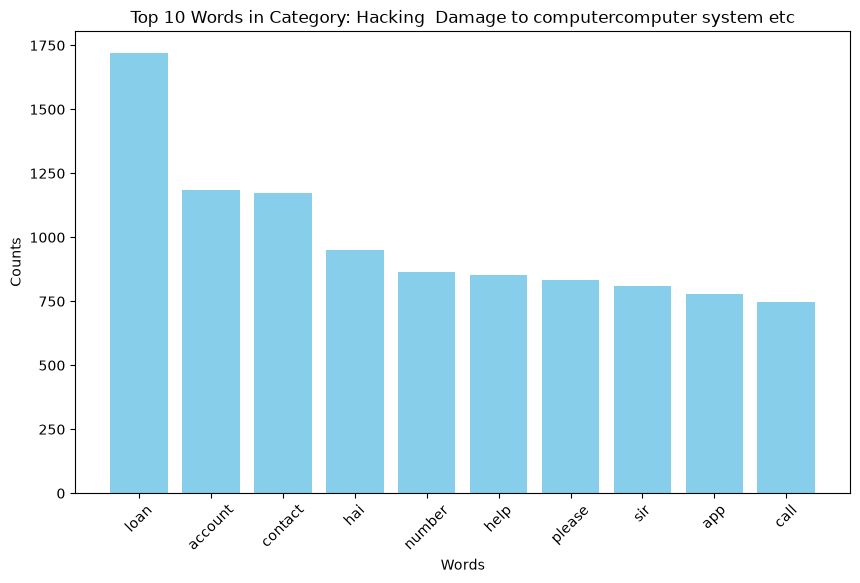

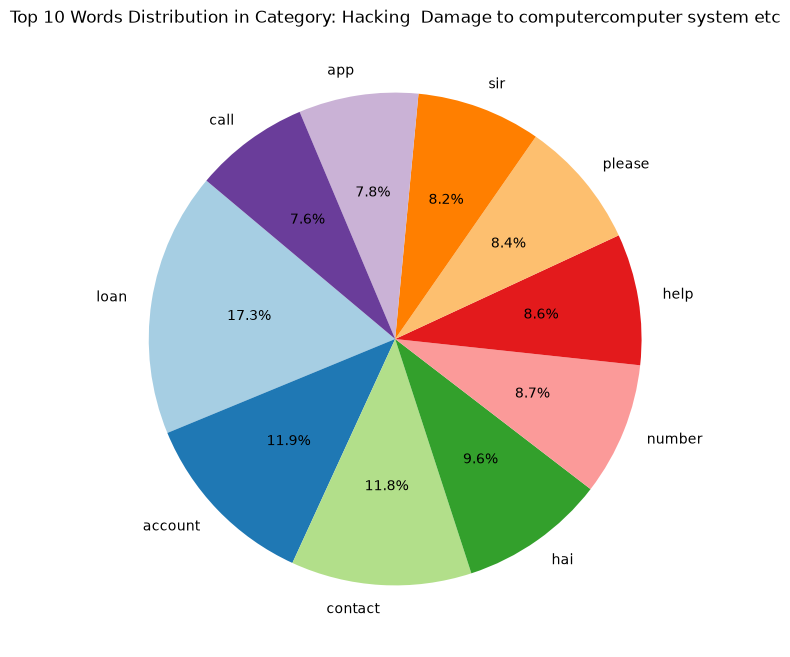

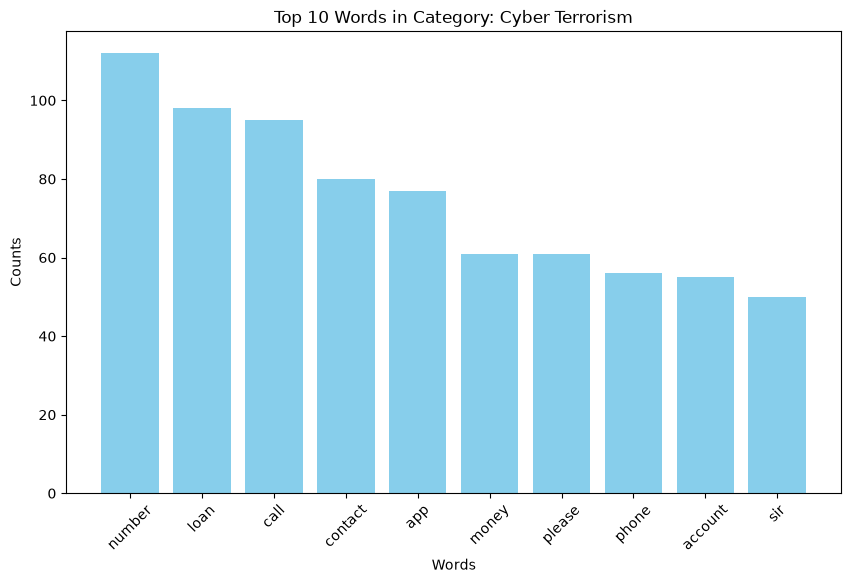

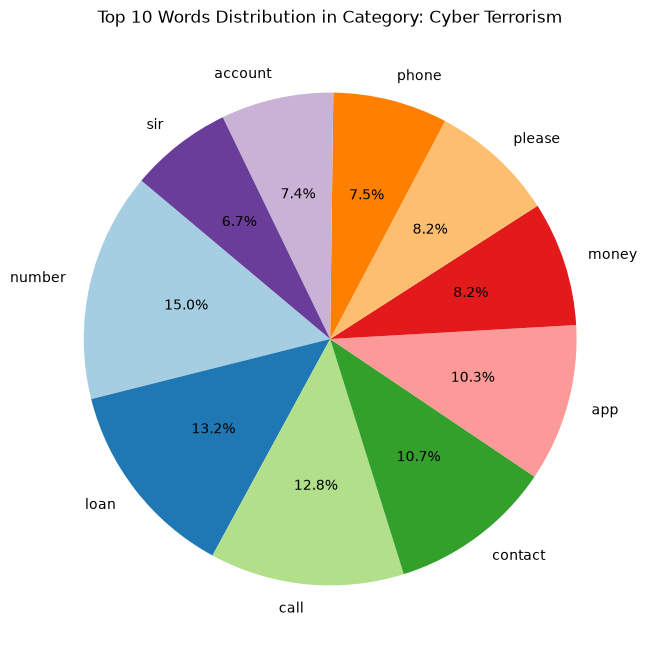

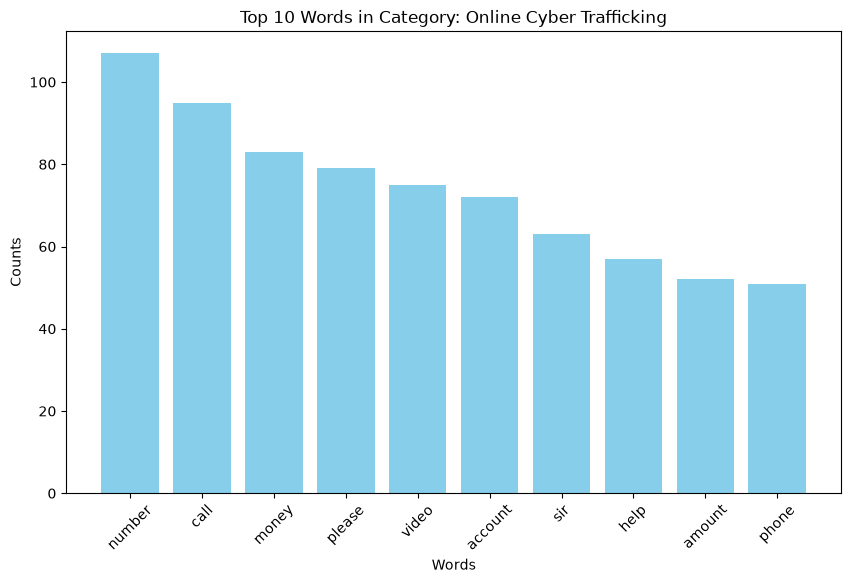

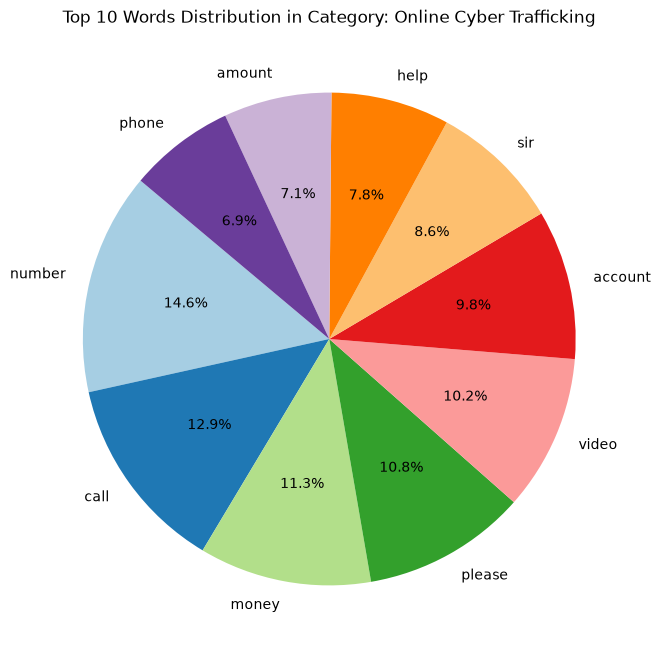

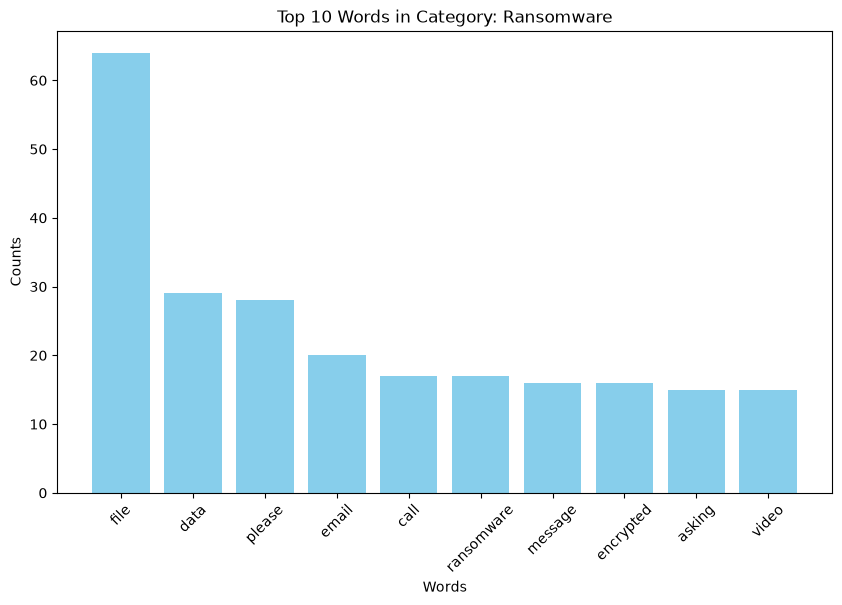

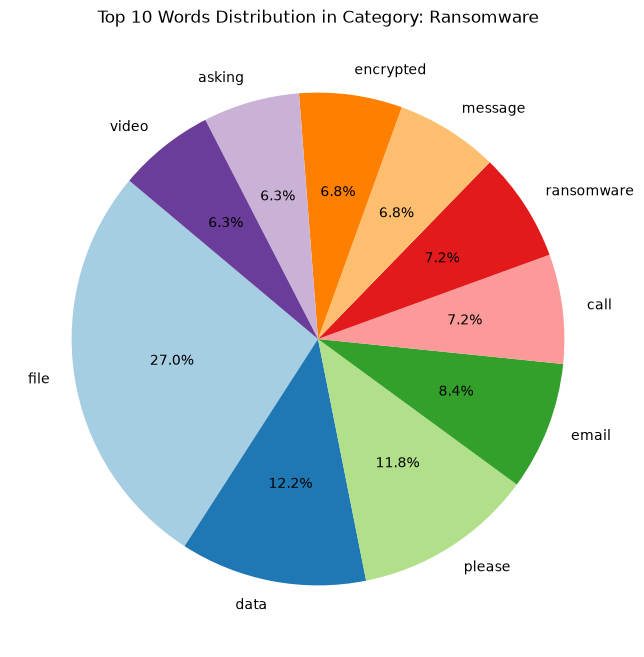

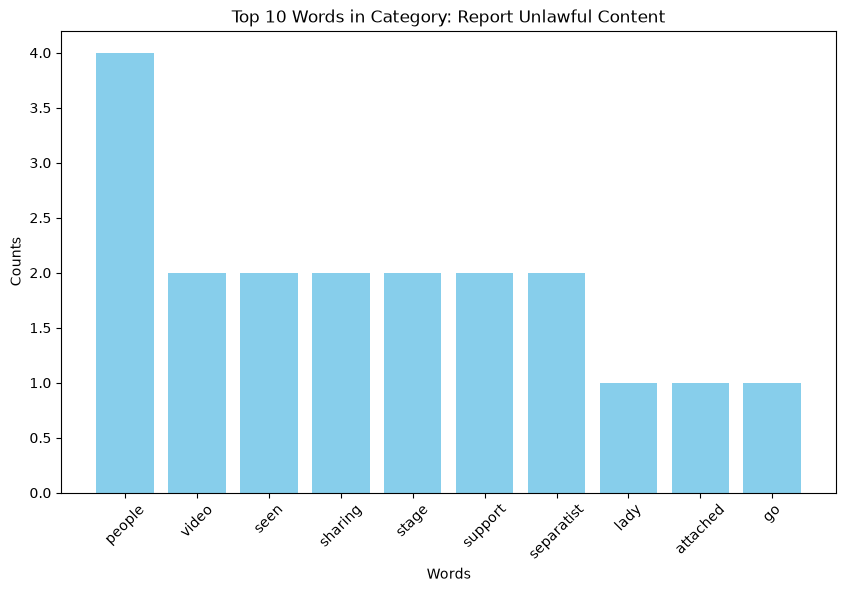

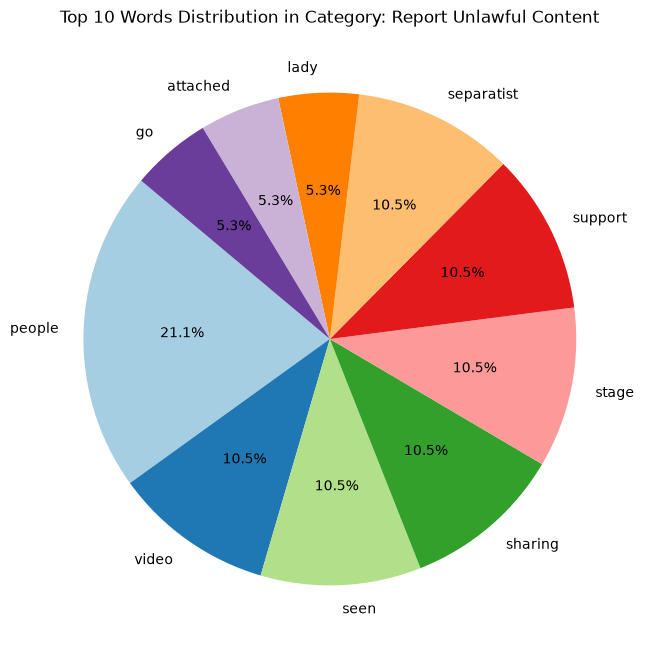

In [18]:
from collections import Counter

def get_top_words(text, num_words=10):
    words = text.split()
    word_counts = Counter(words)
    return word_counts.most_common(num_words)

categories = df['category'].unique()

for category in categories:

    text_for_wordcloud = ' '.join(df[df['category'] == category]['crimeaditionalinfo'])
    
    top_words = get_top_words(text_for_wordcloud)
    words, counts = zip(*top_words)  

    top_words_df = pd.DataFrame(top_words, columns=['Word', 'Count'])

    plt.figure(figsize=(10, 6))
    plt.bar(top_words_df['Word'], top_words_df['Count'], color='skyblue')
    plt.title(f"Top 10 Words in Category: {category}")
    plt.xlabel("Words")
    plt.ylabel("Counts")
    plt.xticks(rotation=45)
    plt.show()

    plt.figure(figsize=(8, 8))
    plt.pie(
        top_words_df['Count'],
        labels=top_words_df['Word'],
        autopct='%1.1f%%',
        colors=plt.cm.Paired.colors,
        startangle=140
    )
    plt.title(f"Top 10 Words Distribution in Category: {category}")
    plt.show()

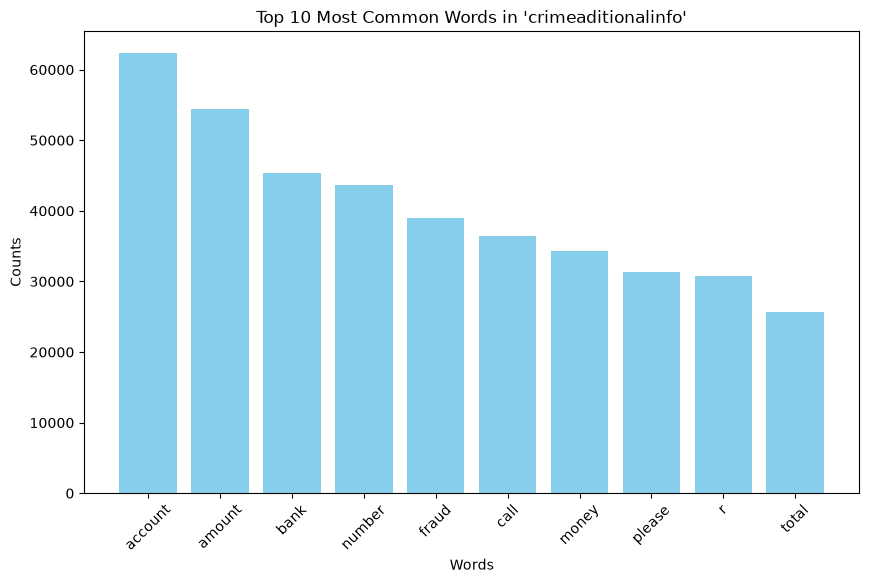

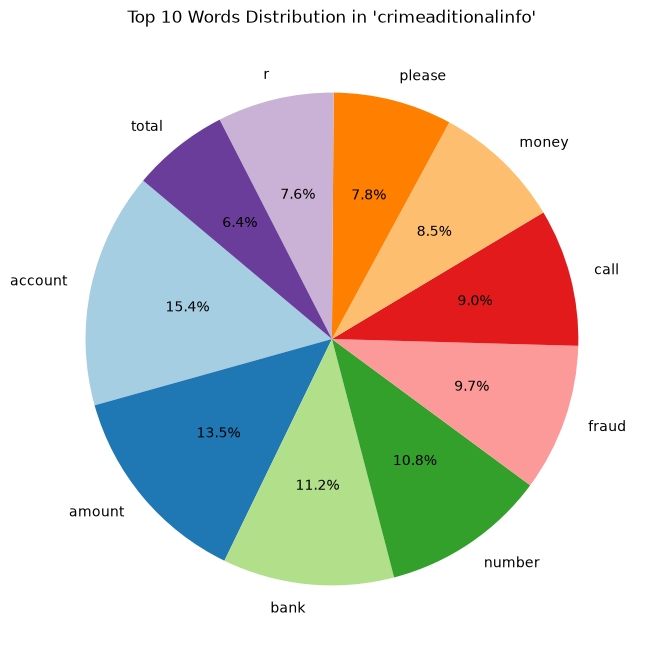

In [19]:
text_for_wordcloud = ' '.join(df['crimeaditionalinfo'])

word_counts = Counter(text_for_wordcloud.split())

top_words = word_counts.most_common(10)
words, counts = zip(*top_words) 

top_words_df = pd.DataFrame(top_words, columns=['Word', 'Count'])

plt.figure(figsize=(10, 6))
plt.bar(top_words_df['Word'], top_words_df['Count'], color='skyblue')
plt.title("Top 10 Most Common Words in 'crimeaditionalinfo'")
plt.xlabel("Words")
plt.ylabel("Counts")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(8, 8))
plt.pie(
    top_words_df['Count'],
    labels=top_words_df['Word'],
    autopct='%1.1f%%',
    colors=plt.cm.Paired.colors,
    startangle=140
)
plt.title("Top 10 Words Distribution in 'crimeaditionalinfo'")
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import SMOTE

In [21]:
df

,category,sub_category,crimeaditionalinfo
0,Online and Social Media Related Crime,Cyber Bullying Stalking Sexting,continue received random call abusive message ...
1,Online Financial Fraud,Fraud CallVishing,fraudster continuously messaging asking pay mo...
2,Online Gambling Betting,Online Gambling Betting,acting like police demanding money adding sect...
3,Online and Social Media Related Crime,Online Job Fraud,apna job applied job interview telecalling res...
4,Online Financial Fraud,Fraud CallVishing,received call lady stating send new phone vivo...
...,...,...,...
93681,Online Financial Fraud,Internet Banking Related Fraud,identity theft smishing sm fraud creditdebit c...
93682,Online Financial Fraud,EWallet Related Fraud,received call number asking phone pay cash bac...
93683,Online Financial Fraud,UPI Related Frauds,cyber stalking blackmailing phonesmsvoip call ...
93684,Online and Social Media Related Crime,Online Matrimonial Fraud,call karke bola ki aapka lotary laga ha aru ac...


In [22]:
label_encoder = LabelEncoder()
df['category_label'] = label_encoder.fit_transform(df['category'])

In [23]:
category_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Category to Label Mapping:", category_mapping)

Category to Label Mapping: {'Any Other Cyber Crime': np.int64(0), 'Cryptocurrency Crime': np.int64(1), 'Cyber Attack/ Dependent Crimes': np.int64(2), 'Cyber Terrorism': np.int64(3), 'Hacking  Damage to computercomputer system etc': np.int64(4), 'Online Cyber Trafficking': np.int64(5), 'Online Financial Fraud': np.int64(6), 'Online Gambling  Betting': np.int64(7), 'Online and Social Media Related Crime': np.int64(8), 'Ransomware': np.int64(9), 'Report Unlawful Content': np.int64(10)}


In [24]:
df

,category,sub_category,crimeaditionalinfo,category_label
0,Online and Social Media Related Crime,Cyber Bullying Stalking Sexting,continue received random call abusive message ...,8
1,Online Financial Fraud,Fraud CallVishing,fraudster continuously messaging asking pay mo...,6
2,Online Gambling Betting,Online Gambling Betting,acting like police demanding money adding sect...,7
3,Online and Social Media Related Crime,Online Job Fraud,apna job applied job interview telecalling res...,8
4,Online Financial Fraud,Fraud CallVishing,received call lady stating send new phone vivo...,6
...,...,...,...,...
93681,Online Financial Fraud,Internet Banking Related Fraud,identity theft smishing sm fraud creditdebit c...,6
93682,Online Financial Fraud,EWallet Related Fraud,received call number asking phone pay cash bac...,6
93683,Online Financial Fraud,UPI Related Frauds,cyber stalking blackmailing phonesmsvoip call ...,6
93684,Online and Social Media Related Crime,Online Matrimonial Fraud,call karke bola ki aapka lotary laga ha aru ac...,8


In [25]:
df = df[['crimeaditionalinfo', 'category_label']]

In [26]:
df

,crimeaditionalinfo,category_label
0,continue received random call abusive message ...,8
1,fraudster continuously messaging asking pay mo...,6
2,acting like police demanding money adding sect...,7
3,apna job applied job interview telecalling res...,8
4,received call lady stating send new phone vivo...,6
...,...,...
93681,identity theft smishing sm fraud creditdebit c...,6
93682,received call number asking phone pay cash bac...,6
93683,cyber stalking blackmailing phonesmsvoip call ...,6
93684,call karke bola ki aapka lotary laga ha aru ac...,8


In [27]:
print(df['category_label'].value_counts().sort_index())

category_label
0     10811
1       473
2      3608
3       161
4      1709
5       183
6     52496
7       444
8     12076
9        56
10        1
Name: count, dtype: int64


In [28]:
df = df[['crimeaditionalinfo', 'category_label']].copy()

df['crimeaditionalinfo'] = df['crimeaditionalinfo'].fillna('').astype(str)
df['category_label'] = pd.to_numeric(df['category_label'], errors='coerce')

df = df.dropna(subset=['category_label'])
df['category_label'] = df['category_label'].astype(int)

class_counts = df['category_label'].value_counts()

print("Original class distribution:")
print(class_counts.sort_index())

valid_classes = class_counts[class_counts >= 2].index

df = df[df['category_label'].isin(valid_classes)].reset_index(drop=True)

X = df['crimeaditionalinfo']
y = df['category_label']

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

print("\nTraining distribution before SMOTE:")
print(y_train.value_counts().sort_index())

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("\nTF-IDF:")
print("X_train:", X_train_tfidf.shape)
print("X_test :", X_test_tfidf.shape)

min_class_count = y_train.value_counts().min()

smote_k = min(5, min_class_count - 1)

smote = SMOTE(
    random_state=42,
    k_neighbors=smote_k
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_tfidf,
    y_train
)

print("\nTraining distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())

print("\nFinal shapes:")
print("X_train:", X_train_smote.shape)
print("y_train:", y_train_smote.shape)
print("X_test :", X_test_tfidf.shape)
print("y_test :", y_test.shape)

Original class distribution:
category_label
0     10811
1       473
2      3608
3       161
4      1709
5       183
6     52496
7       444
8     12076
9        56
10        1
Name: count, dtype: int64

Training samples: 65613
Testing samples: 16404

Training distribution before SMOTE:
category_label
0     8649
1      378
2     2886
3      129
4     1367
5      146
6    41997
7      355
8     9661
9       45
Name: count, dtype: int64

TF-IDF:
X_train: (65613, 10000)
X_test : (16404, 10000)

Training distribution after SMOTE:
category_label
0    41997
1    41997
2    41997
3    41997
4    41997
5    41997
6    41997
7    41997
8    41997
9    41997
Name: count, dtype: int64

Final shapes:
X_train: (419970, 10000)
y_train: (419970,)
X_test : (16404, 10000)
y_test : (16404,)


In [29]:
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

from sklearn.preprocessing import label_binarize

model = MultinomialNB(alpha=1.0)

model.fit(
    X_train_smote,
    y_train_smote
)

y_pred = model.predict(X_test_tfidf)
y_prob = model.predict_proba(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)
recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)
f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class='ovr',
    average='weighted'
)

print("=" * 60)
print("BAYES THEOREM CLASSIFIER - MULTINOMIAL NAIVE BAYES")
print("=" * 60)

print(f"\nAccuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

BAYES THEOREM CLASSIFIER - MULTINOMIAL NAIVE BAYES

Accuracy  : 0.6164
Precision : 0.7915
Recall    : 0.6164
F1-Score  : 0.6720
ROC-AUC   : 0.8852

Classification Report:
              precision    recall  f1-score   support

           0       0.27      0.51      0.36      2162
           1       0.18      0.78      0.30        95
           2       1.00      1.00      1.00       722
           3       0.02      0.06      0.03        32
           4       0.15      0.64      0.25       342
           5       0.00      0.00      0.00        37
           6       0.96      0.62      0.76     10499
           7       0.05      0.30      0.08        89
           8       0.65      0.58      0.61      2415
           9       0.12      0.27      0.16        11

    accuracy                           0.62     16404
   macro avg       0.34      0.48      0.35     16404
weighted avg       0.79      0.62      0.67     16404



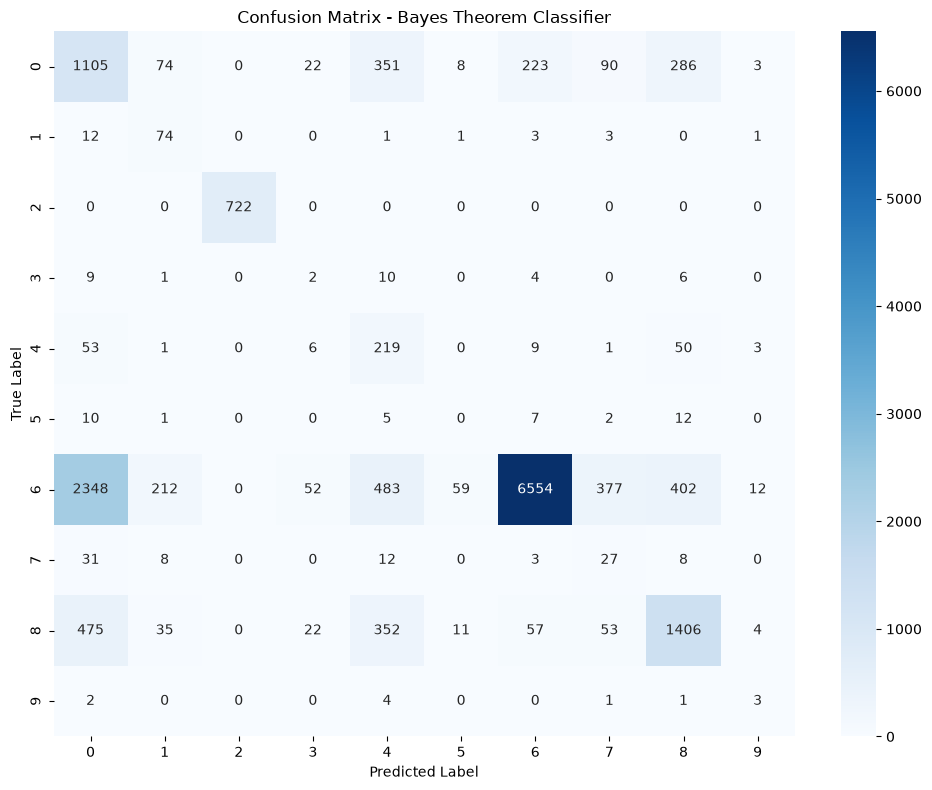

In [30]:
classes = np.sort(np.unique(y_test))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Bayes Theorem Classifier')
plt.tight_layout()
plt.show()